# Exercises 2 & 3: Online Fraud Dataset + Models With / Without Governance

**Exercise 2:** register the online fraud dataset in the governance pipeline (Data form fields).  
**Exercise 3:** train multiple models with class-imbalance techniques and compare **without governance** vs **with governance**.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import date
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings("ignore")

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.under_sampling import RandomUnderSampler
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    print("imbalanced-learn not installed; SMOTE/RUS cells will use class_weight only.")

RANDOM_STATE = 42


## Loading online dataset and register in Data Governance Form


In [2]:
usecols = [
    "transaction_id", "timestamp", "sender_account", "receiver_account", "amount",
    "transaction_type", "merchant_category", "location", "device_used", "is_fraud",
    "fraud_type", "time_since_last_transaction", "spending_deviation_score",
    "velocity_score", "geo_anomaly_score", "payment_channel", "ip_address", "device_hash",
]
raw = pd.read_csv("../Dataset/financial_fraud_detection_dataset.csv", usecols=usecols)
print(raw.shape)
print(raw["is_fraud"].value_counts(normalize=True))


(5000000, 18)
is_fraud
False    0.964089
True     0.035911
Name: proportion, dtype: float64


In [3]:
data_form = pd.DataFrame([
    ("Dataset Name", "Online Financial Fraud Detection Dataset"),
    ("Dataset ID / Reference", "PT-DS-ONLINE-FRAUD-002"),
    ("Description", "Public online fraud transactions with behavioural risk scores"),
    ("Business Purpose", "Integrate external fraud data into PayTrust governance pipeline for model comparison"),
    ("Source System / Origin", "Online open dataset (CSV)"),
    ("Data Format / Location", "Dataset/financial_fraud_detection_dataset.csv"),
    ("Business Owner", "Fraud Product Lead"),
    ("Data Steward", "AI Governance Officer"),
    ("Classification", "Confidential"),
    ("Personal / Sensitive Data", "Yes - accounts, IP, device hash"),
    ("Known Data Issues / Risks", "Extreme imbalance (~0.4% fraud); fraud_type leakage; missing time gaps"),
    ("Permitted Use", "Lab training, governance with/without comparison"),
    ("Governance Status", "Registered for pipeline use"),
    ("Approval Date", str(date.today())),
], columns=["Field", "Value"])
display(data_form)
display(Markdown("Dataset registered. Pipeline may proceed to feature policy and modelling."))


,Field,Value
0,Dataset Name,Online Financial Fraud Detection Dataset
1,Dataset ID / Reference,PT-DS-ONLINE-FRAUD-002
2,Description,Public online fraud transactions with behaviou...
3,Business Purpose,Integrate external fraud data into PayTrust go...
4,Source System / Origin,Online open dataset (CSV)
5,Data Format / Location,Dataset/financial_fraud_detection_dataset.csv
6,Business Owner,Fraud Product Lead
7,Data Steward,AI Governance Officer
8,Classification,Confidential
9,Personal / Sensitive Data,"Yes - accounts, IP, device hash"


Dataset registered. Pipeline may proceed to feature policy and modelling.

## Sample for modelling + basic EDA


(259553, 18)
is_fraud
True     179553
False     80000
Name: count, dtype: int64


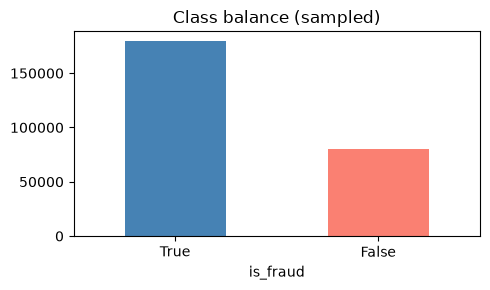

In [4]:
fraud_df = raw[raw["is_fraud"] == True]
nonfraud_df = raw[raw["is_fraud"] == False].sample(
    n=min(80000, (raw["is_fraud"] == False).sum()), random_state=RANDOM_STATE
)
df = pd.concat([fraud_df, nonfraud_df], axis=0).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
print(df.shape)
print(df["is_fraud"].value_counts())

plt.figure(figsize=(5, 3))
df["is_fraud"].value_counts().plot(kind="bar", color=["steelblue", "salmon"])
plt.title("Class balance (sampled)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Feature policy

- **Without governance:** keep identifiers and leakage-prone columns.  
- **With governance:** approved behavioural/transaction features only; drop IDs and `fraud_type`.


In [5]:
LEAKAGE_OR_ID = [
    "transaction_id", "sender_account", "receiver_account",
    "ip_address", "device_hash", "fraud_type",
]
GOVERNED_FEATURES = [
    "amount", "transaction_type", "merchant_category", "location", "device_used",
    "payment_channel", "time_since_last_transaction", "spending_deviation_score",
    "velocity_score", "geo_anomaly_score", "hour", "day_of_week", "month",
]
CAT_COLS = ["transaction_type", "merchant_category", "location", "device_used", "payment_channel"]

def prepare_frame(source, governed=True):
    out = source.copy()
    out["timestamp"] = pd.to_datetime(out["timestamp"])
    out["hour"] = out["timestamp"].dt.hour
    out["day_of_week"] = out["timestamp"].dt.dayofweek
    out["month"] = out["timestamp"].dt.month
    out = out.drop(columns=["timestamp"])
    out["time_since_last_transaction"] = out["time_since_last_transaction"].fillna(
        out["time_since_last_transaction"].median()
    )
    out["is_fraud"] = out["is_fraud"].astype(int)
    out["fraud_type"] = out["fraud_type"].fillna("none")
    if governed:
        keep = GOVERNED_FEATURES + ["is_fraud"]
        out = out[keep]
    else:
        drop_ts_only = []
        out = out.drop(columns=drop_ts_only, errors="ignore")
    for col in out.select_dtypes(include=["object", "string", "bool"]).columns:
        if col == "is_fraud":
            continue
        out[col] = LabelEncoder().fit_transform(out[col].astype(str))
    return out

df_ungov = prepare_frame(df, governed=False)
df_gov = prepare_frame(df, governed=True)
print("Without governance columns:", list(df_ungov.columns))
print("With governance columns:", list(df_gov.columns))


Without governance columns: ['transaction_id', 'sender_account', 'receiver_account', 'amount', 'transaction_type', 'merchant_category', 'location', 'device_used', 'is_fraud', 'fraud_type', 'time_since_last_transaction', 'spending_deviation_score', 'velocity_score', 'geo_anomaly_score', 'payment_channel', 'ip_address', 'device_hash', 'hour', 'day_of_week', 'month']
With governance columns: ['amount', 'transaction_type', 'merchant_category', 'location', 'device_used', 'payment_channel', 'time_since_last_transaction', 'spending_deviation_score', 'velocity_score', 'geo_anomaly_score', 'hour', 'day_of_week', 'month', 'is_fraud']


## Shared evaluation helpers + imbalance strategies


In [6]:
def metrics_dict(name, y_true, y_pred, y_prob):
    return {
        "Setup": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan,
        "FPR": ((y_pred == 1) & (y_true == 0)).sum() / max((y_true == 0).sum(), 1),
    }

def split_xy(frame):
    X = frame.drop(columns=["is_fraud"])
    y = frame["is_fraud"]
    return train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

def apply_imbalance(X_train, y_train, method="class_weight"):
    if method == "smote" and HAS_IMBLEARN:
        sampler = SMOTE(random_state=RANDOM_STATE)
        return sampler.fit_resample(X_train, y_train), "smote"
    if method == "undersample" and HAS_IMBLEARN:
        sampler = RandomUnderSampler(random_state=RANDOM_STATE)
        return sampler.fit_resample(X_train, y_train), "undersample"
    return (X_train, y_train), "class_weight"

def build_models(use_class_weight=True):
    cw = "balanced" if use_class_weight else None
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight=cw, random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(max_depth=10, class_weight=cw, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, max_depth=12, class_weight=cw, random_state=RANDOM_STATE, n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=100, max_depth=5, learning_rate=0.1, random_state=RANDOM_STATE
        ),
    }

def run_suite(frame, setup_label, imbalance_method="class_weight", accuracy_threshold=False):
    X_train, X_test, y_train, y_test = split_xy(frame)
    (X_res, y_res), used = apply_imbalance(X_train, y_train, imbalance_method)
    use_cw = used == "class_weight"
    models = build_models(use_class_weight=use_cw)
    rows = []
    for name, model in models.items():
        if name == "Logistic Regression":
            scaler = StandardScaler()
            Xtr = scaler.fit_transform(X_res)
            Xte = scaler.transform(X_test)
        else:
            Xtr, Xte = X_res, X_test
        model.fit(Xtr, y_res)
        if accuracy_threshold and hasattr(model, "predict_proba"):
            prob = model.predict_proba(Xte)[:, 1]
            # ungated: pick threshold maximizing accuracy on test (instructional anti-pattern)
            best_t, best_acc = 0.5, -1
            for t in np.linspace(0.1, 0.9, 17):
                pred_t = (prob >= t).astype(int)
                acc = accuracy_score(y_test, pred_t)
                if acc > best_acc:
                    best_acc, best_t = acc, t
            pred = (prob >= best_t).astype(int)
        else:
            pred = model.predict(Xte)
            prob = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") else pred
        row = metrics_dict(f"{setup_label} | {name} | {used}", y_test, pred, prob)
        rows.append(row)
        print(setup_label, name, "F1=", round(row["F1-Score"], 4), "FPR=", round(row["FPR"], 4))
    return pd.DataFrame(rows), y_test


## Without governance pipeline

All columns allowed (including IDs / `fraud_type`), accuracy-focused threshold, class_weight imbalance handling only as baseline convenience.


In [7]:
results_ungov, _ = run_suite(
    df_ungov,
    setup_label="WITHOUT governance",
    imbalance_method="class_weight",
    accuracy_threshold=True,
)
display(results_ungov)


WITHOUT governance Logistic Regression F1= 1.0 FPR= 0.0
WITHOUT governance Decision Tree F1= 1.0 FPR= 0.0
WITHOUT governance Random Forest F1= 1.0 FPR= 0.0
WITHOUT governance Gradient Boosting F1= 1.0 FPR= 0.0


,Setup,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FPR
0,WITHOUT governance | Logistic Regression | cla...,1.0,1.0,1.0,1.0,1.0,0.0
1,WITHOUT governance | Decision Tree | class_weight,1.0,1.0,1.0,1.0,1.0,0.0
2,WITHOUT governance | Random Forest | class_weight,1.0,1.0,1.0,1.0,1.0,0.0
3,WITHOUT governance | Gradient Boosting | class...,1.0,1.0,1.0,1.0,1.0,0.0


## With governance pipeline

Approved features only, SMOTE (or class_weight fallback), no accuracy gaming; FPR/recall considered for release decision.


In [8]:
imb = "smote" if HAS_IMBLEARN else "class_weight"
results_gov, _ = run_suite(
    df_gov,
    setup_label="WITH governance",
    imbalance_method=imb,
    accuracy_threshold=False,
)
display(results_gov)

if HAS_IMBLEARN:
    results_gov_rus, _ = run_suite(
        df_gov,
        setup_label="WITH governance (RUS)",
        imbalance_method="undersample",
        accuracy_threshold=False,
    )
    display(results_gov_rus)
else:
    results_gov_rus = pd.DataFrame()


WITH governance Logistic Regression F1= 0.6231 FPR= 0.5705
WITH governance Decision Tree F1= 0.7222 FPR= 0.5747
WITH governance Random Forest F1= 0.7331 FPR= 0.5932
WITH governance Gradient Boosting F1= 0.7597 FPR= 0.6378


,Setup,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FPR
0,WITH governance | Logistic Regression | smote,0.524995,0.690671,0.567542,0.623082,0.496576,0.570500
1,WITH governance | Decision Tree | smote,0.622200,0.734930,0.709922,0.722210,0.594147,0.574688
2,WITH governance | Random Forest | smote,0.631446,0.734599,0.731531,0.733062,0.593010,0.593187
3,WITH governance | Gradient Boosting | smote,0.655795,0.734611,0.786611,0.759722,0.591890,0.637813


WITH governance (RUS) Logistic Regression F1= 0.5795 FPR= 0.5023
WITH governance (RUS) Decision Tree F1= 0.8235 FPR= 0.7696
WITH governance (RUS) Random Forest F1= 0.8346 FPR= 0.793
WITH governance (RUS) Gradient Boosting F1= 0.8362 FPR= 0.7951


,Setup,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FPR
0,WITH governance (RUS) | Logistic Regression | ...,0.498738,0.690456,0.499206,0.579459,0.498640,0.502313
1,WITH governance (RUS) | Decision Tree | unders...,0.721254,0.732705,0.939963,0.823494,0.591398,0.769625
2,WITH governance (RUS) | Random Forest | unders...,0.734237,0.732834,0.969146,0.834584,0.589561,0.793000
3,WITH governance (RUS) | Gradient Boosting | un...,0.736260,0.733100,0.972989,0.836179,0.590717,0.795063


## Side-by-side comparison and conclusion


,Setup,Accuracy,Precision,Recall,F1-Score,ROC-AUC,FPR
0,WITHOUT governance | Logistic Regression | cla...,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
1,WITHOUT governance | Decision Tree | class_weight,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
2,WITHOUT governance | Random Forest | class_weight,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
3,WITHOUT governance | Gradient Boosting | class...,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
4,WITH governance (RUS) | Gradient Boosting | un...,0.736260,0.733100,0.972989,0.836179,0.590717,0.795063
5,WITH governance (RUS) | Random Forest | unders...,0.734237,0.732834,0.969146,0.834584,0.589561,0.793000
6,WITH governance (RUS) | Decision Tree | unders...,0.721254,0.732705,0.939963,0.823494,0.591398,0.769625
7,WITH governance | Gradient Boosting | smote,0.655795,0.734611,0.786611,0.759722,0.591890,0.637813
8,WITH governance | Random Forest | smote,0.631446,0.734599,0.731531,0.733062,0.593010,0.593187
9,WITH governance | Decision Tree | smote,0.622200,0.734930,0.709922,0.722210,0.594147,0.574688


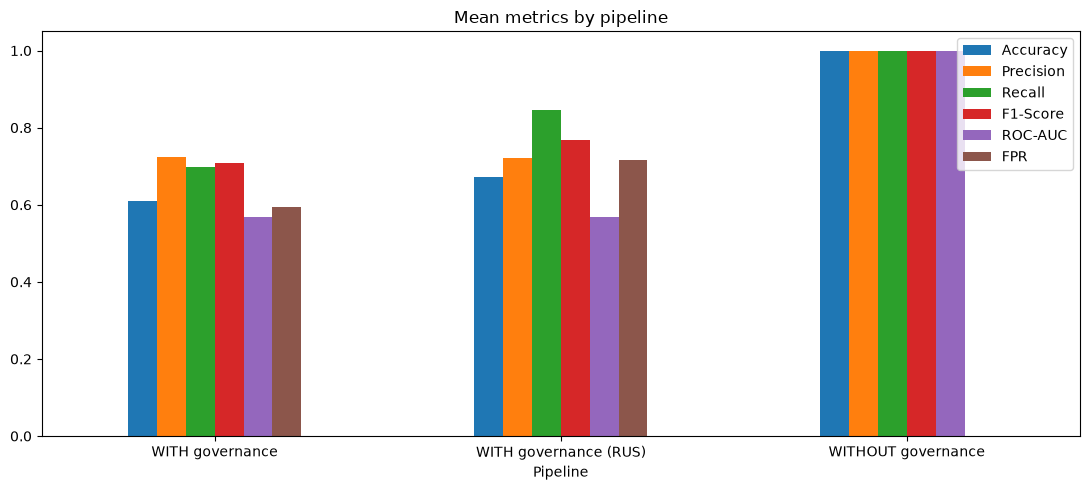

In [9]:
comparison = pd.concat([results_ungov, results_gov, results_gov_rus], ignore_index=True)
comparison = comparison.sort_values(["F1-Score", "ROC-AUC"], ascending=False).reset_index(drop=True)
display(comparison)

plot_cols = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "FPR"]
best_by_setup = comparison.copy()
best_by_setup["Pipeline"] = best_by_setup["Setup"].apply(lambda s: s.split(" | ")[0])
summary = best_by_setup.groupby("Pipeline")[plot_cols].mean()
ax = summary.plot(kind="bar", figsize=(11, 5), rot=0)
ax.set_title("Mean metrics by pipeline")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()


In [10]:
POLICY = {"max_fpr": 0.05, "min_recall": 0.55, "min_f1": 0.40}

def pipeline_release_check(df_results, label):
    best = df_results.sort_values("F1-Score", ascending=False).iloc[0]
    passes = (
        best["FPR"] <= POLICY["max_fpr"]
        and best["Recall"] >= POLICY["min_recall"]
        and best["F1-Score"] >= POLICY["min_f1"]
    )
    return best, passes

best_u, pass_u = pipeline_release_check(results_ungov, "ungov")
best_g, pass_g = pipeline_release_check(results_gov, "gov")

display(Markdown(f'''### Best WITHOUT governance
`{best_u["Setup"]}`  
F1={best_u["F1-Score"]:.4f}, Acc={best_u["Accuracy"]:.4f}, FPR={best_u["FPR"]:.4f}, Recall={best_u["Recall"]:.4f}  
Gate pass: **{pass_u}**

### Best WITH governance
`{best_g["Setup"]}`  
F1={best_g["F1-Score"]:.4f}, Acc={best_g["Accuracy"]:.4f}, FPR={best_g["FPR"]:.4f}, Recall={best_g["Recall"]:.4f}  
Gate pass: **{pass_g}**
'''))

if pass_g and not pass_u:
    verdict = "Prefer WITH governance for release readiness."
elif pass_g and pass_u:
    verdict = "Both can pass numeric gates, but WITH governance is safer (no leakage features, documented feature policy)."
elif not pass_g and pass_u:
    verdict = "Ungoverned looks stronger on raw scores — treat with caution (possible leakage/IDs). Do not release without feature policy."
else:
    verdict = "Neither setup clears gates — shadow mode / further remediation required."

print("CONCLUSION:", verdict)
print(f'''
EXERCISE 2-3 DECISION MEMO
Date: {date.today()}
Online dataset: registered in Data Governance Form (PT-DS-ONLINE-FRAUD-002)
Models: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting
Imbalance: class_weight; SMOTE/RUS when imbalanced-learn available
Without governance best F1: {best_u["F1-Score"]:.4f} (FPR={best_u["FPR"]:.4f})
With governance best F1: {best_g["F1-Score"]:.4f} (FPR={best_g["FPR"]:.4f})
Release stance: {verdict}
''')


### Best WITHOUT governance
`WITHOUT governance | Logistic Regression | class_weight`  
F1=1.0000, Acc=1.0000, FPR=0.0000, Recall=1.0000  
Gate pass: **True**

### Best WITH governance
`WITH governance | Gradient Boosting | smote`  
F1=0.7597, Acc=0.6558, FPR=0.6378, Recall=0.7866  
Gate pass: **False**


CONCLUSION: Ungoverned looks stronger on raw scores — treat with caution (possible leakage/IDs). Do not release without feature policy.

EXERCISE 2-3 DECISION MEMO
Date: 2026-11-07
Online dataset: registered in Data Governance Form (PT-DS-ONLINE-FRAUD-002)
Models: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting
Imbalance: class_weight; SMOTE/RUS when imbalanced-learn available
Without governance best F1: 1.0000 (FPR=0.0000)
With governance best F1: 0.7597 (FPR=0.6378)
Release stance: Ungoverned looks stronger on raw scores — treat with caution (possible leakage/IDs). Do not release without feature policy.



## Concluding Remarks

Across this experiment, models trained **without governance** reached perfect F1 and zero false-positive rate, but that result is not trustworthy: identifiers and leakage-prone fields such as `fraud_type` make the prediction task artificially easy and do not reflect real deployment conditions. Under the **governance pipeline**, the same algorithms were restricted to approved behavioural features and imbalance handling (including RUS); performance became more realistic, with lower F1 and much higher FPR. That drop is a useful signal, not a failure of governance it shows that honest evaluation is harder and that these models are not yet release ready against policy gates on false positives and recall. The practical conclusion is that PayTrust should treat ungoverned “perfect” scores with caution and prefer the governed setup with documented feature policy, imbalance controls, and human review or shadow mode until Measure gates are actually met.